# El padró de Barcelona: una anàlisi demogràfica amb Python

+ **Assignatura:** Taller de Nous Usos de la Informàtica (TNUI)
+ **Durada estimada:** 4 hores
+ **Eines:** Python · pandas · matplotlib
+ **Dades:** Padró Municipal d'Habitants · Ajuntament de Barcelona (Open Data BCN)

---

## Objectius d'aprenentatge

Al final d'aquesta pràctica seràs capaç de:

1. **Carregar i explorar** fitxers CSV reals amb pandas.
2. **Identificar i gestionar** valors nuls i dades emmascades.
3. **Unir** múltiples fitxers en un únic DataFrame coherent.
4. **Transformar i agregar** dades per obtenir indicadors demogràfics.
5. **Visualitzar** tendències temporals i distribucions amb matplotlib.
6. **Comunicar** resultats amb claredat, justificant cada decisió.


> **Nota:** Les cel·les marcades amb 🔧 contenen codi que has d'escriure o completar.
> Les marcades amb ✅ ja estan resoltes i serveixen de guia.


## Com trobar ajuda sobre pandas

  Dins del notebook (la manera més ràpida):
  
  + `df.groupby?`          # docstring del mètode
  + `help(pd.merge)`       # documentació completa
  + `pd.DataFrame.<TAB>`   # autocompletat de mètodes
  
  Referència oficial:
  - Guia d'usuari (https://pandas.pydata.org/docs/user_guide/index.html) — conceptes amb exemples (filtratge, agrupació, joins…)
  - API Reference (https://pandas.pydata.org/docs/reference/index.html) — tots els mètodes, paràmetre per paràmetre

  Full de ruta ràpid:
  - Pandas Cheat Sheet (PDF) (https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf) — les operacions més habituals en una pàgina

  Quan estàs encallat:
  1. Comprova l'estat de les dades amb `df.info()`, `df.head()` i `df.dtypes`.
  2. Descriu el problema a la IA amb: quines columnes tens + quin resultat esperes.

  ---
## Com trobar ajuda sobre matplotlib

  Dins del notebook:
  + `plt.plot?`            # docstring de la funció
  + `help(plt.subplots)`   # paràmetres detallats
  
  Referència oficial:
  - Tutorials per a principiants (https://matplotlib.org/stable/tutorials/index.html) — des de la primera figura fins a subplots avançats
  - API Reference: pyplot (https://matplotlib.org/stable/api/pyplot_summary.html) — totes les funcions de plt.*
  - Galeria d'exemples (https://matplotlib.org/stable/gallery/index.html) — busca el tipus de gràfic que necessites i copia el codi

  Patrons habituals en aquesta pràctica:
  ```python
  fig, ax = plt.subplots(figsize=(10, 5))
  ax.plot(x, y, color="steelblue", label="Sèrie A")
  ax.bar(categories, valors, color="salmon")
  ax.set_title("Títol")
  ax.set_xlabel("Eix X"); ax.set_ylabel("Eix Y")
  ax.legend()
  ax.yaxis.set_major_formatter(
      plt.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))  # format milers
  plt.tight_layout()
  plt.savefig("grafic.png", bbox_inches="tight", dpi=150)
  ```
  
  Quan estàs encallat:
  - Matplotlib Cheat Sheets (PDF) (https://matplotlib.org/cheatsheets/) — 3 fulls: beginner, intermediate, tips & tricks
  - Cerca a la galeria pel tipus de gràfic: línia, barres, àrea apilada, scatter…


## Configuració inicial

Executa aquesta cel·la abans de començar. Importa les biblioteques necessàries i defineix les rutes de dades.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import glob
import os

# Ruta base de les dades (ajusta si cal)
BASE = "./data"
PATH_POBLACIO  = os.path.join(BASE, "poblacio_lloc_naix")
PATH_EDAT      = os.path.join(BASE, "edat_lloc_naix")
PATH_DOMICILIS = os.path.join(BASE, "domicilis_estructura")
PATH_DIMS      = os.path.join(BASE, "pad_dimensions.csv")

# Estil de gràfics
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
})

print("✓ Configuració carregada correctament")


✓ Configuració carregada correctament



## Part 1 — Exploració inicial: un sol any (2026)

Comencem carregant **un únic fitxer** per entendre l'estructura de les dades
abans d'escalar a tota la sèrie temporal.


### 1.1 ✅ Càrrega del fitxer

El dataset `poblacio_lloc_naix` conté el cens agregat per lloc de
naixement i sexe, a nivell de **secció censal**, per a cada barri i districte
de Barcelona. Hi ha **un fitxer CSV per any** (1997–2026).

> La secció censal és la unitat territorial de menor tamany a la que es divideix Espanya. Aquesta secció s'utilitza per la organització de estadístiques demogràfiques.


In [2]:
# ✅ Exemple de càrrega — executeu per veure l'estructura
df_2026 = pd.read_csv(os.path.join(PATH_POBLACIO, "2026_poblacio_lloc_naix.csv"))
print("Shape:", df_2026.shape)
print()
df_2026.head(8)

Shape: (11082, 10)



,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,AEB,Seccio_Censal,Valor,LLOC_NAIX,SEXE
0,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,158,1,1
1,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,171,1,2
2,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,36,2,1
3,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,23,2,2
4,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,68,3,1
5,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,82,3,2
6,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,55,4,1
7,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,60,4,2


### 1.2 🔧 Inspecció bàsica

Respon les preguntes següents explorant el DataFrame. Escriu codi a cada cel·la.


**a) Quines columnes té el dataset i de quin tipus és cadascuna?**

In [3]:
df_2026.info()

<class 'pandas.DataFrame'>
RangeIndex: 11082 entries, 0 to 11081
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Data_Referencia  11082 non-null  str  
 1   Codi_Districte   11082 non-null  int64
 2   Nom_Districte    11082 non-null  str  
 3   Codi_Barri       11082 non-null  int64
 4   Nom_Barri        11082 non-null  str  
 5   AEB              11082 non-null  int64
 6   Seccio_Censal    11082 non-null  int64
 7   Valor            11082 non-null  str  
 8   LLOC_NAIX        11082 non-null  int64
 9   SEXE             11082 non-null  int64
dtypes: int64(6), str(4)
memory usage: 865.9 KB


**b) Quants valors nuls hi ha per columna?**

> Busca la definició de valor nul de pandas. Tingues en compte que si hi ha valors nuls que no tenen aquets format no els detectarà com a valors nuls.

In [4]:
# Contar els valors nuls (NaN) de cada columna
df_2026.isna().sum()

Data_Referencia    0
Codi_Districte     0
Nom_Districte      0
Codi_Barri         0
Nom_Barri          0
AEB                0
Seccio_Censal      0
Valor              0
LLOC_NAIX          0
SEXE               0
dtype: int64

**c) La columna `Valor` hauria de ser numèrica, però pot contenir el caràcter `..`
(dada emmascada per protecció de la privacitat quan el recompte és molt baix).
Quantes files contenen `..`? Quin percentatge representen?**

> Per que creus que l'ajuntament ha d'emmascarar dades?

> El ajuntament podria fer-ho per que no sigui facil identificar alguns ciutadans. Si la combinació de diverses dades dona un resultat de 4 o 5 persones, seria molt senzill identificar a aquestes persones.


In [5]:
# Contar files amb '..'
num_emmascarades = (df_2026['Valor'] == '..').sum()

# Calcular percentatge
total_files = len(df_2026)
percentatge = (num_emmascarades / total_files) * 100

print(f"Files amb '..': {num_emmascarades}")
print(f"Percentatge: {percentatge:.2f}%")

Files amb '..': 412
Percentatge: 3.72%


**d) Quants valors únics té la columna `LLOC_NAIX`?
Llista'ls. Com interpretes aquest resultat?**

> 💡 *Pista:* Consulta el fitxer `pad_dimensions.csv` per entendre els codis.


In [6]:
# La columna LLOC_NAIX té 6 valors possibles. Barcelona ciutat, Resta de Catalunya, Resta d'Espanya, Resta de la Unió Europea, Resta del món i No consta.

# Llistar els valors únics
valors_unics = df_2026['LLOC_NAIX'].unique()
print(f"Valors únics: {valors_unics}")

# Comptar quants valors únics hi ha
num_valors = df_2026['LLOC_NAIX'].nunique()
print(f"Nombre de valors únics: {num_valors}")

Valors únics: [1 2 3 4 5 6]
Nombre de valors únics: 6


### 1.3 ✅ Diccionari de codis

El fitxer `pad_dimensions.csv` conté les descripcions de tots els codis
utilitzats al padró. Carrega'l i filtra els codis de la dimensió `LLOC_NAIX`.


In [7]:
# ✅ Càrrega del diccionari de dimensions
dims = pd.read_csv(PATH_DIMS)
print("Dimensions disponibles:")
print(dims[["Codi_Dimensio","Desc_Dimensio"]].drop_duplicates().to_string(index=False))

Dimensions disponibles:
 Codi_Dimensio          Desc_Dimensio
             1                   SEXE
             2                 EDAT_1
             3                 EDAT_Q
             4              LLOC_NAIX
             5         LLOC_NAIX_CCAA
             6        LLOC_NAIX_REGIO
             7         NACIONALITAT_G
             8     NACIONALITAT_REGIO
             9         NIV_EDUCA_esta
            10                 DECADA
            11         LLOC_NAIX_PAIS
            12    LLOC_NAIX_CONTINENT
            13      NACIONALITAT_PAIS
            14 NACIONALITAT_CONTINENT
            15         N_PERSONES_AGG
            16         TIPUS_DOMICILI
            17              DOM_00_18
            18              DOM_18_64
            19              DOM_65_99
            20              DOM_DONES
            21              DOM_HOMES
            22  NACIONALITAT_DOMICILI
            23          CONTINENT_MOV
            24        CODI_BARRI_DEST
            25       NACIO

In [8]:
# ✅ Codis de LLOC_NAIX (dimensió 4)
lloc_naix_dict = dims[dims["Desc_Dimensio"] == "LLOC_NAIX"][["Codi_Valor","Desc_Valor_CA"]
].rename(columns={"Codi_Valor": "LLOC_NAIX", "Desc_Valor_CA": "Lloc_Naix_Label"})
print(lloc_naix_dict.to_string(index=False))

 LLOC_NAIX          Lloc_Naix_Label
         1         Barcelona ciutat
         2       Resta de Catalunya
         3          Resta d’Espanya
         4 Resta de la Unió Europea
         5            Resta del món
         6                No consta


### 1.4 🔧 Comprensió dels codis

Ara que coneixes els codis, respon:

**a) Quants codis numèrics de `LLOC_NAIX` corresponen a categories agregades?
Quina és la interpretació de cadascun?**


In [9]:
# Hi ha 6 categories agregades
codis_agregats = lloc_naix_dict[lloc_naix_dict['LLOC_NAIX'].astype(str).isin(['1', '2', '3', '4', '5', '6'])]
print(codis_agregats.to_string(index=False))

# 1 -> Barcelona ciutat
# 2 -> Resta de Catalunya
# 3 -> Resta d'Espanya
# 4 -> Resta de la Unió Europea
# 5 -> Resta del món
# 6 -> No consta

 LLOC_NAIX          Lloc_Naix_Label
         1         Barcelona ciutat
         2       Resta de Catalunya
         3          Resta d’Espanya
         4 Resta de la Unió Europea
         5            Resta del món
         6                No consta


**b) Per a l'any 2026, calcula la **població total** de Barcelona
filtrant només els codis agregats (1–6) i sumant `Valor`.**

> ⚠️ Recorda convertir `Valor` a numèric abans de sumar
> (`pd.to_numeric(..., errors='coerce')`).


In [10]:
# Convertim Valor a numèric (els valors ".." passen a ser NaN) i filtrem els codis 1-6
df_2026_filtrat = df_2026[df_2026["LLOC_NAIX"].isin(range(1, 7))].copy()
df_2026_filtrat["Valor_Num"] = pd.to_numeric(df_2026_filtrat["Valor"], errors="coerce")

poblacio_total_2026 = int(df_2026_filtrat["Valor_Num"].sum())
diferencia_oficial = 1729963 - poblacio_total_2026

print(f"Població total calculada (2026): {poblacio_total_2026:,} persones")
print(f"Població oficial (2026):         1,729,963 persones")
print(f"Diferència:                      {diferencia_oficial:,} persones")


Població total calculada (2026): 1,729,409 persones
Població oficial (2026):         1,729,963 persones
Diferència:                      554 persones


**c) El resultat és lleugerament inferior a la xifra oficial de 1.729.963
empadronats. A quina causa ho atribueixes?
Escriu la teva hipòtesi com a comentari en el codi.**


In [11]:
# 🔧 Explica la hipòtesi aquí com a comentari Python
# El resultat obtingut (1.729.409 habitants) és 554 persones inferior a la xifra oficial (1.729.963)
# a causa de les 412 files que tenen el valor emmascarat amb ".." per secret estadístic i protecció
# de la privacitat (quan una combinació de secció censal, lloc de naixement i sexe té molt pocs individus,
# habitualment entre 1 i 4 persones). En convertir ".." a NaN, aquests petits recomptes no se sumen.


---
## Part 2 — Neteja i transformació

Ara que entens l'estructura, construeix un **DataFrame net i reutilitzable**
per al 2026, llest per a l'anàlisi.


### 2.1 🔧 Funció de neteja

Escriu una funció `netejar_poblacio(path)` que:

1. Llegeix el CSV des de `path`.
2. Converteix `Valor` a numèric (tractant `..` com a `NaN`).
3. Filtra **només** les files amb `LLOC_NAIX` entre 1 i 6.
4. Extreu l'any de la columna `Data_Referencia` i l'afegeixes com a nova columna `Any`.
5. Retorna el DataFrame net.

> 💡 *Pista:* `pd.to_datetime(df["Data_Referencia"]).dt.year`


In [12]:
def netejar_poblacio(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["Valor"] = pd.to_numeric(df["Valor"], errors="coerce")
    df = df[df["LLOC_NAIX"].isin(range(1, 7))].copy()
    df["Any"] = pd.to_datetime(df["Data_Referencia"]).dt.year
    return df

# Prova la funció amb l'any 2026
df_net = netejar_poblacio(os.path.join(PATH_POBLACIO, "2026_poblacio_lloc_naix.csv"))
print("Shape net:", df_net.shape)
df_net.head()


Shape net: (11082, 11)


,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,AEB,Seccio_Censal,Valor,LLOC_NAIX,SEXE,Any
0,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,158.0,1,1,2026
1,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,171.0,1,2,2026
2,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,36.0,2,1,2026
3,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,23.0,2,2,2026
4,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,68.0,3,1,2026


### 2.2 🔧 Agregació a nivell de ciutat

El DataFrame net té dades a nivell de **secció censal**.
Agrega'l per obtenir el total de la **ciutat sencera** per a cada
combinació de `(Any, LLOC_NAIX, SEXE)`.

> Informa't sobre l'operador `groupby` de pandas i fes-lo servir.


In [13]:
# 🔧 Agrega per Any, LLOC_NAIX i SEXE
df_ciutat = (
    df_net
    .groupby(["Any", "LLOC_NAIX", "SEXE"], as_index=False)["Valor"]
    .sum()
)

# Verifica: hauries de tenir 12 files (6 llocs × 2 sexes)
print("Files:", len(df_ciutat))
df_ciutat


Files: 12


,Any,LLOC_NAIX,SEXE,Valor
0,2026,1,1,394793.0
1,2026,1,2,376703.0
2,2026,2,1,62495.0
3,2026,2,2,54312.0
4,2026,3,1,124666.0
5,2026,3,2,89546.0
6,2026,4,1,42325.0
7,2026,4,2,42079.0
8,2026,5,1,273421.0
9,2026,5,2,269064.0


### 2.3 🔧 Unió amb el diccionari

Uneix `df_ciutat` amb `lloc_naix_dict` per afegir l'etiqueta
descriptiva a cada codi `LLOC_NAIX`.

> Informa't sobre l'operador `merge` de pandas i fes-lo servir.



In [14]:
# 🔧 Uneix df_ciutat amb lloc_naix_dict
df_ciutat = pd.merge(df_ciutat, lloc_naix_dict, on="LLOC_NAIX", how="left")
df_ciutat


,Any,LLOC_NAIX,SEXE,Valor,Lloc_Naix_Label
0,2026,1,1,394793.0,Barcelona ciutat
1,2026,1,2,376703.0,Barcelona ciutat
2,2026,2,1,62495.0,Resta de Catalunya
3,2026,2,2,54312.0,Resta de Catalunya
4,2026,3,1,124666.0,Resta d’Espanya
5,2026,3,2,89546.0,Resta d’Espanya
6,2026,4,1,42325.0,Resta de la Unió Europea
7,2026,4,2,42079.0,Resta de la Unió Europea
8,2026,5,1,273421.0,Resta del món
9,2026,5,2,269064.0,Resta del món


### 2.4 🔧 Taula resum

Crea una taula pivot que mostri, per a 2026, la **població per lloc de
naixement** (files) i **sexe** (columnes), amb el total com a fila final.

> 💡 *Pista:* `pd.pivot_table(...)`

> Una taula pivot és una eina d’anàlisi de dades que permet resumir i reorganitzar la informació d’una taula original per facilitar-ne la interpretació. En aquest cas, la taula pivot ha de mostrar la població de l’any 2026 agrupada per lloc de naixement a les files i per sexe a les columnes, calculant el nombre total de persones per a cada combinació. A més, ha d’incloure una fila final amb els totals generals, de manera que es pugui comparar fàcilment la distribució de la població segons aquestes dues variables.


In [15]:
# 🔧 Taula pivot per a 2026: població per lloc de naixement (files) i sexe (columnes) amb totals
sexe_dict = dims[dims["Desc_Dimensio"] == "SEXE"][["Codi_Valor", "Desc_Valor_CA"]].rename(
    columns={"Codi_Valor": "SEXE", "Desc_Valor_CA": "Sexe_Label"}
)

taula_resum = (
    df_ciutat
    .merge(sexe_dict, on="SEXE", how="left")
    .pivot_table(
        values="Valor",
        index="Lloc_Naix_Label",
        columns="Sexe_Label",
        aggfunc="sum",
        margins=True,
        margins_name="Total"
    )
    .astype(int)
)

# Ordenem les files segons l'ordre dels codis 1-6 i deixem "Total" al final
ordre_files = list(lloc_naix_dict["Lloc_Naix_Label"]) + ["Total"]
taula_resum = taula_resum.reindex(ordre_files)
taula_resum


Sexe_Label,Dona,Home,Total
Lloc_Naix_Label,,,
Barcelona ciutat,394793,376703,771496
Resta de Catalunya,62495,54312,116807
Resta d’Espanya,124666,89546,214212
Resta de la Unió Europea,42325,42079,84404
Resta del món,273421,269064,542485
No consta,5,0,5
Total,897705,831704,1729409


### 2.5 🔧 Reflexió: qualitat de les dades

Escriu com a text (cel·la Markdown) una breu reflexió (3-5 frases) sobre:
- Quines decisions de neteja has pres i per què.
- Quin impacte tenen els valors `..` en l'anàlisi.
- Quin risc hi ha d'introduir biaixos si s'ignoren sense documentar.


Per netejar el dataset hem convertit la columna `Valor` a tipus numèric amb `pd.to_numeric(..., errors="coerce")`, transformant els codis `'..'` en `NaN`, hem filtrat els codis vàlids de `LLOC_NAIX` (1–6) i hem extret l'any de la data de referència. A nivell agregat de tota la ciutat, l'impacte dels valors emmascarats `'..'` és molt reduït en termes relatius: representen el 3,72% de les files (412 cel·les el 2026), però només suposen 554 persones sobre 1.729.963 empadronats (un 0,03% de la població total). Tanmateix, aquest emmascarament no es distribueix a l'atzar, sinó que es concentra en les combinacions amb freqüències molt baixes (com ara la categoria «No consta» o grups minoritaris en determinades seccions censals). Si s'ignoren aquests valors sense documentar-ho, es corre el risc d'infravalorar sistemàticament la presència de col·lectius minoritaris o d'introduir biaixos quan es fan anàlisis desagregades a escala de barri o secció censal.


---
## Part 3 — Sèrie temporal 1997–2026

Ara escala la teva funció de neteja als **30 fitxers** disponibles
per construir la sèrie temporal completa.


### 3.1 🔧 Càrrega de tots els anys

Usa `glob.glob()` per obtenir la llista de fitxers i aplica
`netejar_poblacio()` a cadascun. Concatena els resultats en un
únic DataFrame `df_serie`.


In [16]:
fitxers = sorted(glob.glob(os.path.join(PATH_POBLACIO, "*.csv")))
print(f"Fitxers trobats: {len(fitxers)}")

# 🔧 Carrega tots els anys i concatena
df_serie = pd.concat([netejar_poblacio(f) for f in fitxers], ignore_index=True)

print("Shape total:", df_serie.shape)
print("Anys disponibles:", sorted(df_serie["Any"].unique()))


Fitxers trobats: 30


Shape total: (328341, 11)
Anys disponibles: [np.int32(1997), np.int32(1998), np.int32(1999), np.int32(2000), np.int32(2001), np.int32(2002), np.int32(2003), np.int32(2004), np.int32(2005), np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


### 3.2 🔧 Consistència entre anys

Abans de continuar, **verifica la consistència** del dataset combinat:

**a)** Hi ha algun any amb un nombre de files significativament diferent
de la resta? Quina podria ser la causa?


In [17]:
# 🔧 Recompte de files i seccions censals per any
resum_anys = (
    df_serie
    .groupby("Any")
    .agg(
        Files=("Valor", "size"),
        Seccions_Censals=("Seccio_Censal", "nunique"),
        Files_No_Consta=("LLOC_NAIX", lambda s: (s == 6).sum())
    )
)
print(resum_anys.to_string())
print(f"\nMínim de files: {resum_anys['Files'].min()} ({resum_anys['Files'].idxmin()}) | Màxim de files: {resum_anys['Files'].max()} ({resum_anys['Files'].idxmax()})")

# Explicació:
# No hi ha cap any amb un nombre de files dràsticament diferent (tots oscil·len entre 10.695 el 1997 i 11.082 el 2024-2026).
# Aquesta petita variació progressiva s'explica per dues causes:
# 1) Les combinacions (Seccio_Censal, LLOC_NAIX, SEXE) amb 0 persones empadronades (especialment el codi 6 "No consta")
#    no s'inclouen com a files als CSV; amb els anys han aparegut més seccions amb algun cas de codi 6 (de 85 a 402 files).
# 2) El nombre de seccions censals de Barcelona ha variat lleugerament per ajustos administratius (de 1.065 el 1997 a 1.068 des del 2010).


      Files  Seccions_Censals  Files_No_Consta
Any                                           
1997  10695              1065               85
1998  10716              1065               93
1999  10746              1067              114
2000  10784              1067              148
2001  10829              1067              185
2002  10886              1068              231
2003  10945              1068              271
2004  10988              1068              315
2005  11027              1068              350
2006  11061              1068              382
2007  11045              1068              365
2008  11040              1068              360
2009  10924              1068              244
2010  10866              1068              186
2011  10884              1068              204
2012  10891              1068              211
2013  10895              1068              215
2014  10901              1068              221
2015  10926              1068              246
2016  10931  

**b)** Per a cada any (1997-2026), calcula la **població total** (suma de tots els
codis 1–6, tots dos sexes). Representa'la com a gràfic de línies.


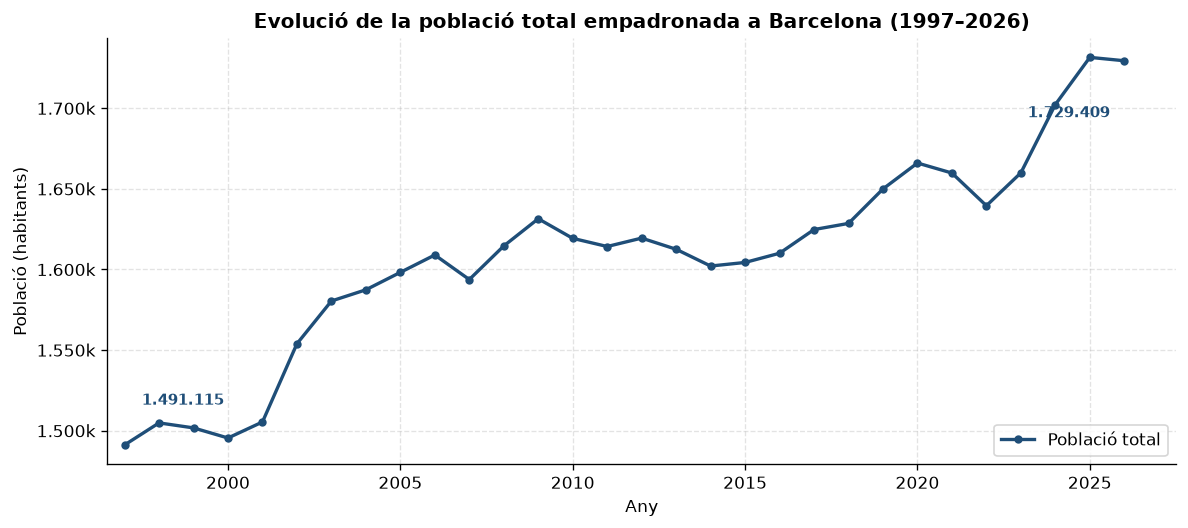

In [18]:
# 🔧 Població total per any (1997-2026) i gràfic de línies
pob_anual = (
    df_serie
    .groupby("Any", as_index=False)["Valor"]
    .sum()
    .rename(columns={"Valor": "Poblacio_Total"})
)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pob_anual["Any"], pob_anual["Poblacio_Total"], color="#1f4e78", marker="o", markersize=4, linewidth=2, label="Població total")

ax.set_title("Evolució de la població total empadronada a Barcelona (1997–2026)", fontsize=12, fontweight="bold")
ax.set_xlabel("Any")
ax.set_ylabel("Població (habitants)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000):,}k".replace(",", ".")))
ax.set_xlim(1996.5, 2027.5)

# Anotem el valor inicial i final
pob_1997 = int(pob_anual.loc[pob_anual["Any"] == 1997, "Poblacio_Total"].values[0])
pob_2026 = int(pob_anual.loc[pob_anual["Any"] == 2026, "Poblacio_Total"].values[0])
ax.annotate(f"{pob_1997:,}".replace(",", "."), xy=(1997, pob_1997), xytext=(1997.5, pob_1997 + 25000), fontsize=9, fontweight="bold", color="#1f4e78")
ax.annotate(f"{pob_2026:,}".replace(",", "."), xy=(2026, pob_2026), xytext=(2023.2, pob_2026 - 35000), fontsize=9, fontweight="bold", color="#1f4e78")

ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 3.3 🔧 Agregació per lloc de naixement

Per a la visualització principal, necessites la **suma total** (ambdós
sexes) de cada `LLOC_NAIX` per any.

Per resoldre l’exercici, es recomana utilitzar un encadenament d’operacions de Pandas (method chaining) similar al següent exemple:

```python
serie_lloc = (
    df_serie
    .groupby(["Any", "LLOC_NAIX"], as_index=False)["Valor"]
    .sum()
    .rename(columns={"Valor": "Total"})
)
```

Aquest estil de programació permet expressar de manera clara i concisa les diferents transformacions aplicades al conjunt de dades. En aquest exercici, es demana construir la taula pivot mitjançant un encadenament d’instruccions similar, combinant operacions com ara el filtratge de l’any 2026, la creació de la taula pivot, el càlcul de totals i el canvi de noms de columnes quan sigui necessari. L’objectiu és que el codi sigui llegible, fàcil de mantenir i coherent amb les bones pràctiques habituals en anàlisi de dades amb Pandas.

Crea un DataFrame `serie_lloc` amb columnes: `Any`, `LLOC_NAIX`,
`Lloc_Naix_Label`, `Total`.


In [19]:
# 🔧 Agregació per Any i LLOC_NAIX amb method chaining
serie_lloc = (
    df_serie
    .groupby(["Any", "LLOC_NAIX"], as_index=False)["Valor"]
    .sum()
    .rename(columns={"Valor": "Total"})
    .merge(lloc_naix_dict, on="LLOC_NAIX", how="left")
    [["Any", "LLOC_NAIX", "Lloc_Naix_Label", "Total"]]
)

print("Shape serie_lloc:", serie_lloc.shape)
serie_lloc.tail(6)


Shape serie_lloc: (180, 4)


,Any,LLOC_NAIX,Lloc_Naix_Label,Total
174,2026,1,Barcelona ciutat,771496.0
175,2026,2,Resta de Catalunya,116807.0
176,2026,3,Resta d’Espanya,214212.0
177,2026,4,Resta de la Unió Europea,84404.0
178,2026,5,Resta del món,542485.0
179,2026,6,No consta,5.0


### 3.4 🔧 Visualització: sèrie temporal

Fés un gràfic amb quatre línies (BCN, Resta Catalunya, Resta Espanya, Resta del món)
des del 1997 fins al 2026.

Requisits del gràfic:
- Títol i etiquetes dels eixos en català.
- Llegenda clara.
- Etiqueta amb el valor final de cada línia (2026) a la dreta.
- Paleta de colors coherent.
- Una anotació que marqui algun moment clau que pot haver tingut impacgte en la població (ex: crisi 2008, pandèmia 2020).

> 💡 Per al grup "Resta del món", agrupa els codis 4, 5 i 6.


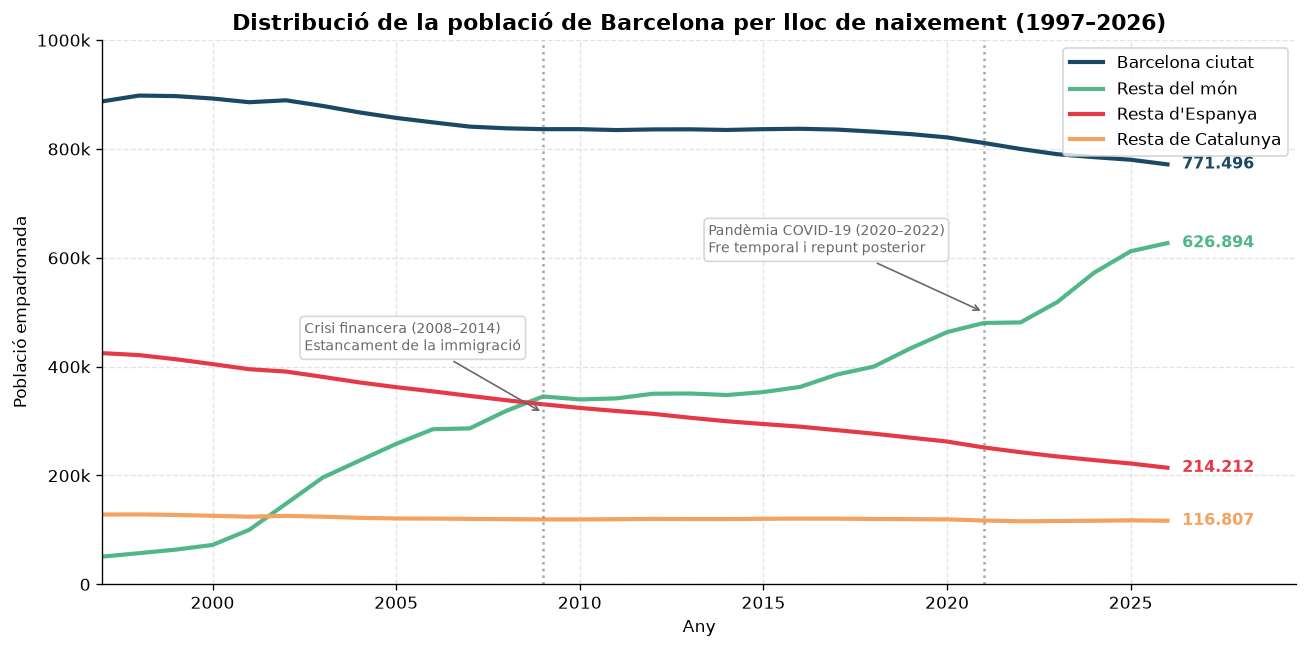

In [20]:
# 🔧 Gràfic de 4 línies: BCN (1), Resta Catalunya (2), Resta Espanya (3) i Resta del món (4, 5, 6)
serie_4grups = (
    serie_lloc
    .assign(
        Grup=lambda d: d["LLOC_NAIX"].map({
            1: "Barcelona ciutat",
            2: "Resta de Catalunya",
            3: "Resta d'Espanya",
            4: "Resta del món",
            5: "Resta del món",
            6: "Resta del món",
        })
    )
    .groupby(["Any", "Grup"], as_index=False)["Total"]
    .sum()
)

colors = {
    "Barcelona ciutat": "#1b4965",
    "Resta del món": "#52b788",
    "Resta d'Espanya": "#e63946",
    "Resta de Catalunya": "#f4a261",
}

ordre_grups = ["Barcelona ciutat", "Resta del món", "Resta d'Espanya", "Resta de Catalunya"]

fig, ax = plt.subplots(figsize=(11, 5.5))

for grup in ordre_grups:
    sub = serie_4grups[serie_4grups["Grup"] == grup].sort_values("Any")
    ax.plot(sub["Any"], sub["Total"], label=grup, color=colors[grup], linewidth=2.5)
    val_2026 = int(sub.loc[sub["Any"] == 2026, "Total"].values[0])
    ax.annotate(
        f"{val_2026:,}".replace(",", "."),
        xy=(2026, val_2026),
        xytext=(2026.4, val_2026),
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color=colors[grup],
    )

# Anotació de moments clau (crisi 2008 i pandèmia 2020)
ax.axvline(2009, color="gray", linestyle=":", alpha=0.7)
ax.annotate(
    "Crisi financera (2008–2014)\nEstancament de la immigració",
    xy=(2009, 315000),
    xytext=(2002.5, 430000),
    arrowprops=dict(arrowstyle="->", color="dimgray", lw=1),
    fontsize=8.5,
    color="dimgray",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="lightgray", alpha=0.9),
)

ax.axvline(2021, color="gray", linestyle=":", alpha=0.7)
ax.annotate(
    "Pandèmia COVID-19 (2020–2022)\nFre temporal i repunt posterior",
    xy=(2021, 500000),
    xytext=(2013.5, 610000),
    arrowprops=dict(arrowstyle="->", color="dimgray", lw=1),
    fontsize=8.5,
    color="dimgray",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="lightgray", alpha=0.9),
)

ax.set_title("Distribució de la població de Barcelona per lloc de naixement (1997–2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Any")
ax.set_ylabel("Població empadronada")
ax.set_xlim(1997, 2029.5)
ax.set_ylim(0, 1000000)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k" if x > 0 else "0"))
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("grafic_serie.png", bbox_inches="tight", dpi=150)
plt.show()


---
## Part 4 — Estructura dels domicilis (2026)

Canviem de dataset: ara analitzem com es distribueixen els
**684.077 domicilis** de Barcelona per tipus d'estructura familiar.


### 4.1 🔧 Càrrega i exploració

Carrega `2026_domicilis_estructura.csv`.
Fes una inspecció equivalent a la de la Part 1:
shape, dtypes, nuls, valors únics de `TIPUS_DOMICILI`.


In [21]:
# 🔧 Càrrega i exploració de 2026_domicilis_estructura.csv
df_dom = pd.read_csv(os.path.join(PATH_DOMICILIS, "2026_domicilis_estructura.csv"))

print("Shape:", df_dom.shape)
print("\nTipus de dades:")
print(df_dom.dtypes)
print("\nValors nuls per columna:")
print(df_dom.isna().sum())
print("\nFiles amb '..':", (df_dom["Valor"].astype(str) == "..").sum())
print("\nValors únics de TIPUS_DOMICILI:", sorted(df_dom["TIPUS_DOMICILI"].unique()))
print("Nombre de categories de TIPUS_DOMICILI:", df_dom["TIPUS_DOMICILI"].nunique())
df_dom.head()


Shape: (12768, 9)

Tipus de dades:
Data_Referencia      str
Codi_Districte     int64
Nom_Districte        str
Codi_Barri         int64
Nom_Barri            str
AEB                int64
Seccio_Censal      int64
Valor              int64
TIPUS_DOMICILI     int64
dtype: object

Valors nuls per columna:
Data_Referencia    0
Codi_Districte     0
Nom_Districte      0
Codi_Barri         0
Nom_Barri          0
AEB                0
Seccio_Censal      0
Valor              0
TIPUS_DOMICILI     0
dtype: int64

Files amb '..': 0

Valors únics de TIPUS_DOMICILI: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Nombre de categories de TIPUS_DOMICILI: 12


,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,AEB,Seccio_Censal,Valor,TIPUS_DOMICILI
0,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,66,1
1,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,78,2
2,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,27,3
3,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,18,4
4,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,97,5


### 4.2 ✅ Diccionari de TIPUS_DOMICILI


In [22]:
# ✅ Codis de TIPUS_DOMICILI (dimensió 16)
tipus_dict = dims[dims["Desc_Dimensio"] == "TIPUS_DOMICILI"][
    ["Codi_Valor","Desc_Valor_CA"]
].rename(columns={"Codi_Valor": "TIPUS_DOMICILI",
                   "Desc_Valor_CA": "Tipus_Label"})
print(tipus_dict.to_string(index=False))


 TIPUS_DOMICILI                                                                 Tipus_Label
              1                                                    Una dona de 18 a 64 anys
              2                                                     Un home de 18 a 64 anys
              3                                                   Una dona de 65 anys i més
              4                                                    Un home de 65 anys i més
              5                                               Dues persones de 18 a 64 anys
              6                                              Dues persones de 65 anys i més
              7                      Dues persones: una de 18-64 anys i l'altra de 65 i més
              8                                 Dues persones o més totes majors de 18 anys
              9 Dues persones o més: una dona de 18 anys i més amb altres menors de 18 anys
             10  Dues persones o més: un home de 18 anys i més amb altres menors

### 4.3 🔧 Agregació i unió

Calcula el **nombre total de domicilis** per a cada codi `TIPUS_DOMICILI`
a nivell de tota la ciutat. Uneix amb `tipus_dict` per tenir l'etiqueta.
Ordena per nombre de domicilis de major a menor.


In [23]:
# 🔧 Agregació de domicilis per TIPUS_DOMICILI, unió amb tipus_dict i ordenació
df_dom["Valor"] = pd.to_numeric(df_dom["Valor"], errors="coerce")

dom_ciutat = (
    df_dom
    .groupby("TIPUS_DOMICILI", as_index=False)["Valor"]
    .sum()
    .rename(columns={"Valor": "Domicilis"})
    .merge(tipus_dict, on="TIPUS_DOMICILI", how="left")
    .sort_values("Domicilis", ascending=False)
    .reset_index(drop=True)
)

dom_ciutat["Percentatge"] = (dom_ciutat["Domicilis"] / dom_ciutat["Domicilis"].sum()) * 100
print(f"Total de domicilis a Barcelona (2026): {dom_ciutat['Domicilis'].sum():,}".replace(",", "."))
dom_ciutat[["TIPUS_DOMICILI", "Tipus_Label", "Domicilis", "Percentatge"]]


Total de domicilis a Barcelona (2026): 684.077


,TIPUS_DOMICILI,Tipus_Label,Domicilis,Percentatge
0,8,Dues persones o més totes majors de 18 anys,130861,19.129572
1,5,Dues persones de 18 a 64 anys,92297,13.492195
2,11,Tres persones o més: dues de 18 anys i més i l...,77502,11.329426
3,3,Una dona de 65 anys i més,70498,10.305565
4,1,Una dona de 18 a 64 anys,61792,9.032901
5,2,Un home de 18 a 64 anys,61729,9.023692
6,6,Dues persones de 65 anys i més,59174,8.650196
7,12,Altres domicilis amb una o més persones menors...,49133,7.182379
8,7,Dues persones: una de 18-64 anys i l'altra de ...,37460,5.475992
9,4,Un home de 65 anys i més,24203,3.538052


### 4.4 🔧 Visualització: estructura dels domicilis

Crea un **gràfic de barres horitzontals** que mostri els 12 tipus
de domicili, amb:
- Etiquetes descriptives (del diccionari) a l'eix Y.
- Percentatge sobre el total al costat de cada barra.
- Colors que diferenciïn les llars unipersonals, les de dos, les de tres o més
  i les que inclouen menors.


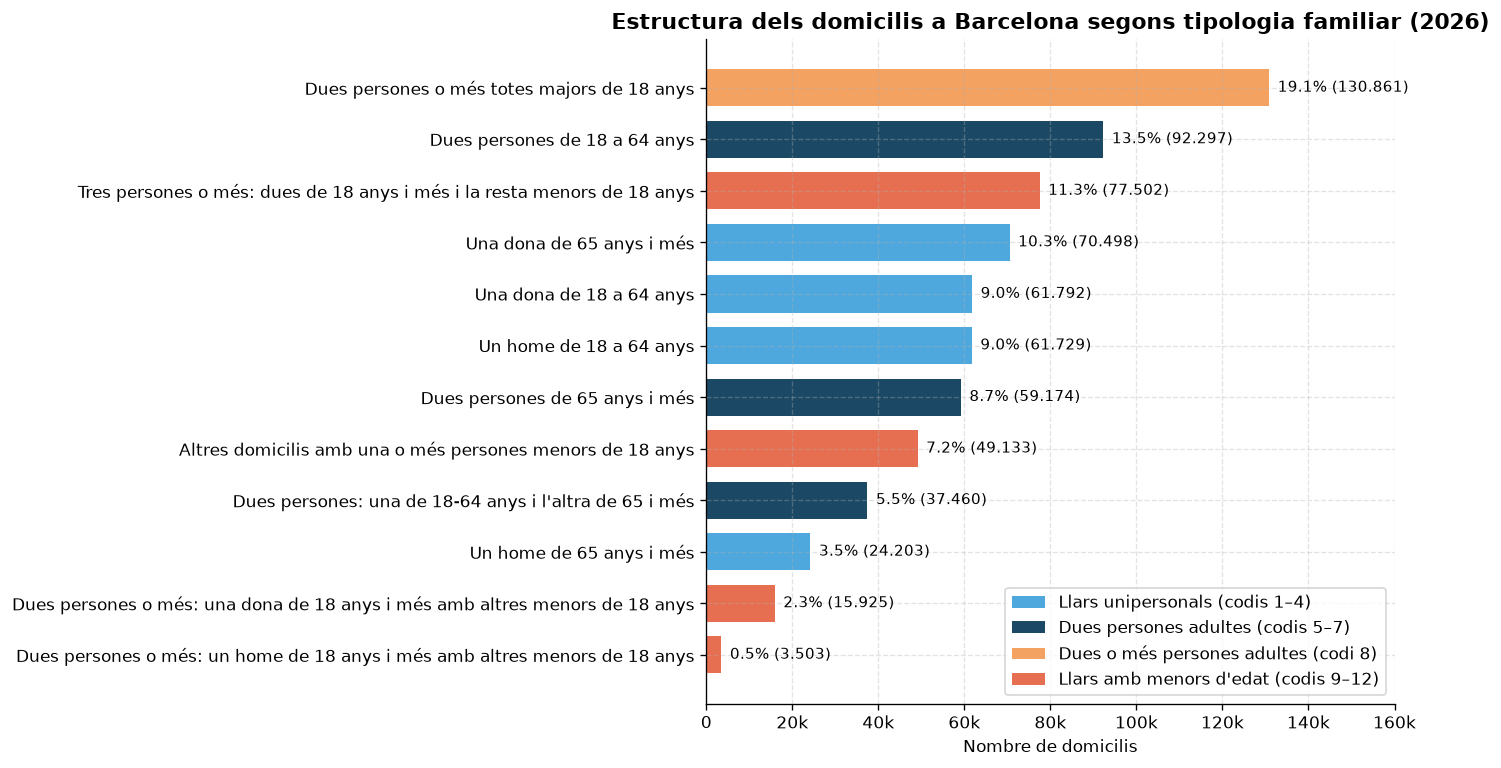

In [24]:
# 🔧 Gràfic de barres horitzontals dels 12 tipus de domicili
from matplotlib.patches import Patch

# Ordenem de menor a major perquè la barra més gran quedi a dalt en barh
dom_plot = dom_ciutat.sort_values("Domicilis", ascending=True).copy()

def color_tipus(codi):
    if codi in [1, 2, 3, 4]:
        return "#4ea8de"   # Llars unipersonals
    elif codi in [5, 6, 7]:
        return "#1b4965"   # Llars de dues persones adultes
    elif codi == 8:
        return "#f4a261"   # Dues o més persones adultes (sense menors)
    else:
        return "#e76f51"   # Llars amb presència de menors (9-12)

bar_colors = [color_tipus(c) for c in dom_plot["TIPUS_DOMICILI"]]

fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.barh(dom_plot["Tipus_Label"], dom_plot["Domicilis"], color=bar_colors, height=0.72)

for bar, pct, val in zip(bars, dom_plot["Percentatge"], dom_plot["Domicilis"]):
    ax.text(
        bar.get_width() + 2000,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}% ({val:,})".replace(",", "."),
        va="center",
        fontsize=9,
    )

ax.set_title("Estructura dels domicilis a Barcelona segons tipologia familiar (2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Nombre de domicilis")
ax.set_xlim(0, 160000)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k" if x > 0 else "0"))

legend_elements = [
    Patch(facecolor="#4ea8de", label="Llars unipersonals (codis 1–4)"),
    Patch(facecolor="#1b4965", label="Dues persones adultes (codis 5–7)"),
    Patch(facecolor="#f4a261", label="Dues o més persones adultes (codi 8)"),
    Patch(facecolor="#e76f51", label="Llars amb menors d'edat (codis 9–12)"),
]
ax.legend(handles=legend_elements, loc="lower right", frameon=True)

plt.tight_layout()
plt.show()


### 4.5 🔧 Indicadors clau

Calcula i imprimeix:

a) Nombre i percentatge de domicilis on viu **una única persona**.
b) Nombre i percentatge de domicilis amb **presència de menors** (codis 9–12).
c) Comparació entre **dones soles ≥ 65 anys** i **homes sols ≥ 65 anys**.
   Quina és la ràtio? Quin fenomen sociodemogràfic reflecteix?


In [25]:
# 🔧 Indicadors clau dels domicilis (2026)
total_domicilis = dom_ciutat["Domicilis"].sum()

# a) Llars unipersonals (codis 1, 2, 3, 4)
unipersonals = dom_ciutat[dom_ciutat["TIPUS_DOMICILI"].isin([1, 2, 3, 4])]["Domicilis"].sum()
pct_unipersonals = (unipersonals / total_domicilis) * 100

# b) Llars amb presència de menors (codis 9, 10, 11, 12)
amb_menors = dom_ciutat[dom_ciutat["TIPUS_DOMICILI"].isin([9, 10, 11, 12])]["Domicilis"].sum()
pct_menors = (amb_menors / total_domicilis) * 100

# c) Dones soles >= 65 anys (codi 3) vs Homes sols >= 65 anys (codi 4)
dones_65 = dom_ciutat.loc[dom_ciutat["TIPUS_DOMICILI"] == 3, "Domicilis"].values[0]
homes_65 = dom_ciutat.loc[dom_ciutat["TIPUS_DOMICILI"] == 4, "Domicilis"].values[0]
ratio_dones_homes_65 = dones_65 / homes_65

print(f"a) Domicilis unipersonals:        {unipersonals:,} ({pct_unipersonals:.2f}%)".replace(",", "."))
print(f"b) Domicilis amb menors (9–12):   {amb_menors:,} ({pct_menors:.2f}%)".replace(",", "."))
print(f"c) Dones soles >= 65 anys:        {dones_65:,}".replace(",", "."))
print(f"   Homes sols >= 65 anys:         {homes_65:,}".replace(",", "."))
print(f"   Ràtio dones/homes (>=65 anys): {ratio_dones_homes_65:.2f} dones per cada home")
print("\nFenomen sociodemogràfic:")
print("Hi ha gairebé el triple de dones grans que viuen soles que no pas homes (ràtio 2,91). Això reflecteix")
print("principalment la major esperança de vida femenina combinada amb el fet que, en les generacions de més edat,")
print("les dones solien casar-se amb homes d'edat igual o superior, donant lloc a una incidència molt més alta")
print("de viduïtat femenina en edats avançades.")


a) Domicilis unipersonals:        218.222 (31.90%)
b) Domicilis amb menors (9–12):   146.063 (21.35%)
c) Dones soles >= 65 anys:        70.498
   Homes sols >= 65 anys:         24.203
   Ràtio dones/homes (>=65 anys): 2.91 dones per cada home

Fenomen sociodemogràfic:
Hi ha gairebé el triple de dones grans que viuen soles que no pas homes (ràtio 2,91). Això reflecteix
principalment la major esperança de vida femenina combinada amb el fet que, en les generacions de més edat,
les dones solien casar-se amb homes d'edat igual o superior, donant lloc a una incidència molt més alta
de viduïtat femenina en edats avançades.


---
## Part 5 — Edat mitjana per lloc de naixement (2026)

Fins ara hem analitzat *quants* residents hi ha de cada origen.
Ara ens preguntem: *quina edat mitjana* té cada grup?
Aquesta informació és clau per entendre els fluxos migratoris
i les necessitats de serveis socials.


### 5.1 ✅ Estructura del dataset d'edat quinquennal

El fitxer `2026_edat_lloc_naix.csv` conté la població desagregada per
**grups d'edat quinquennals** (`EDAT_Q`), lloc de naixement i sexe.


In [26]:
# ✅ Carrega el dataset d'edat
df_edat = pd.read_csv(os.path.join(PATH_EDAT, "2026_edat_lloc_naix.csv"))
df_edat["Valor"] = pd.to_numeric(df_edat["Valor"], errors="coerce")
print("Shape:", df_edat.shape)
df_edat.head()


Shape: (14730, 9)


,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,Valor,LLOC_NAIX,EDAT_Q,SEXE
0,2026-01-01,1,Ciutat Vella,1,el Raval,813.0,1,0,1
1,2026-01-01,1,Ciutat Vella,1,el Raval,851.0,1,0,2
2,2026-01-01,1,Ciutat Vella,1,el Raval,648.0,1,1,1
3,2026-01-01,1,Ciutat Vella,1,el Raval,726.0,1,1,2
4,2026-01-01,1,Ciutat Vella,1,el Raval,526.0,1,2,1


### 5.2 ✅ Diccionari de grups d'edat quinquennals


In [27]:
# ✅ Codis EDAT_Q (dimensió 3)
edat_q_dict = dims[dims["Desc_Dimensio"] == "EDAT_Q"][
    ["Codi_Valor","Desc_Valor_CA"]
].rename(columns={"Codi_Valor":"EDAT_Q","Desc_Valor_CA":"Edat_Label"})
print(edat_q_dict.to_string(index=False))


 EDAT_Q Edat_Label
      0    <5 anys
      1   5-9 anys
      2 10-14 anys
      3 15-19 anys
      4 20-24 anys
      5 25-29 anys
      6 30-34 anys
      7 35-39 anys
      8 40-44 anys
      9 45-49 anys
     10 50-54 anys
     11 55-59 anys
     12 60-64 anys
     13 65-69 anys
     14 70-74 anys
     15 75-79 anys
     16 80-84 anys
     17 85-89 anys
     18 90-94 anys
     19 95-99 anys
     20  ≥100 anys
     21  No consta


### 5.3 🔧 Punt mig de cada grup

Per calcular l'edat mitjana ponderada necessitem assignar un
**punt mig** a cada grup quinquennal.

Completa el diccionari `MIDPOINTS` seguint la lògica:
- Grup 0 (<5 anys) → 2 anys
- Grup 1 (5-9 anys) → 7 anys
- …
- Grup 20 (≥100 anys) → 100 anys
- Grup 21 (No consta) → `None` (s'ha d'excloure del càlcul)


In [28]:
# 🔧 Completa el diccionari de punts mig
MIDPOINTS = {i: i * 5 + 2 for i in range(20)}   # grups 0–19 (2, 7, 12, ..., 97)
MIDPOINTS[20] = 100   # ≥ 100 anys
MIDPOINTS[21] = None  # No consta → s'exclou

# Comprova que tens 21 valors numèrics (grup 21 és None)
assert sum(1 for v in MIDPOINTS.values() if v is not None) == 21
print("✓ MIDPOINTS correcte")


✓ MIDPOINTS correcte


### 5.4 🔧 Càlcul de l'edat mitjana ponderada

L'**edat mitjana ponderada** de cada grup es calcula com:

$$\bar{E} = \frac{\sum_i \text{midpoint}_i \cdot \text{poblaci\'o}_i}{\sum_i \text{poblaci\'o}_i}$$

Implementa la funció `edat_mitjana_per_lloc(df, midpoints)` que:
1. Afegeixi una columna `midpoint` a partir de `EDAT_Q`.
2. Exclogui les files amb `EDAT_Q == 21` (No consta).
3. Calculi l'edat mitjana per a cada codi `LLOC_NAIX` (1–6).
4. Retorni un DataFrame amb columnes `LLOC_NAIX` i `Edat_Mitjana`.

> 💡 Pista: `groupby(...).apply(lambda g: ...)`


In [29]:
def edat_mitjana_per_lloc(df: pd.DataFrame, midpoints: dict) -> pd.DataFrame:
    df_valid = df[(df["EDAT_Q"] != 21) & (df["LLOC_NAIX"].isin(range(1, 7)))].copy()
    df_valid["midpoint"] = df_valid["EDAT_Q"].map(midpoints)
    df_valid["edat_ponderada"] = df_valid["midpoint"] * df_valid["Valor"]

    agregat = (
        df_valid
        .groupby("LLOC_NAIX", as_index=False)
        .agg(
            Suma_Ponderada=("edat_ponderada", "sum"),
            Poblacio=("Valor", "sum"),
        )
    )
    agregat["Edat_Mitjana"] = agregat["Suma_Ponderada"] / agregat["Poblacio"]
    return agregat[["LLOC_NAIX", "Edat_Mitjana"]]

edat_m = edat_mitjana_per_lloc(df_edat, MIDPOINTS)
edat_m = edat_m.merge(lloc_naix_dict, on="LLOC_NAIX")
print(edat_m.to_string(index=False))


 LLOC_NAIX  Edat_Mitjana          Lloc_Naix_Label
         1     41.399045         Barcelona ciutat
         2     49.930071       Resta de Catalunya
         3     65.842986          Resta d’Espanya
         4     38.732642 Resta de la Unió Europea
         5     38.977925            Resta del món
         6     32.000000                No consta


### 5.5 🔧 Visualització i interpretació

**a)** Crea un gràfic de barres verticals que mostri l'edat mitjana
de cada grup de lloc de naixement, amb:
- Colors coherents amb els del gràfic de sèrie temporal.
- El valor numèric a sobre de cada barra.
- Una línia horitzontal discontínua que marqui l'edat mitjana global de la ciutat.

> 💡 Edat mitjana global estimada: calcula-la tu mateix a partir del dataset.


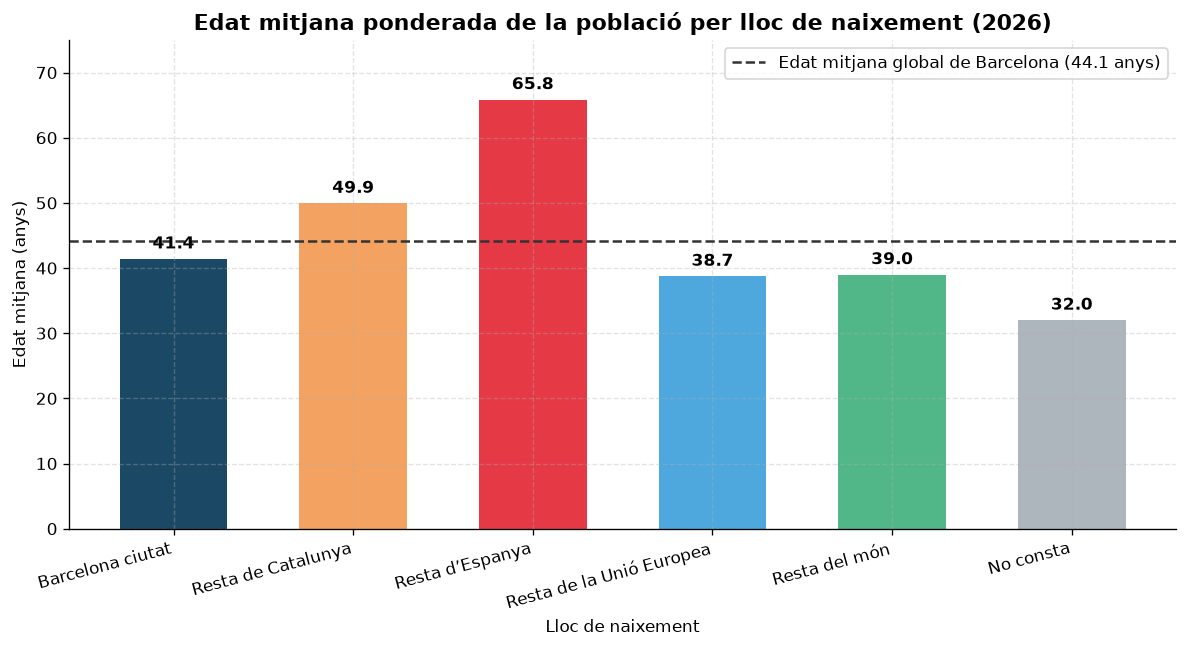

In [30]:
# 🔧 Gràfic d'edat mitjana per lloc de naixement
# Calculem l'edat mitjana global de la ciutat
df_edat_valid = df_edat[(df_edat["EDAT_Q"] != 21) & (df_edat["LLOC_NAIX"].isin(range(1, 7)))].copy()
df_edat_valid["midpoint"] = df_edat_valid["EDAT_Q"].map(MIDPOINTS)
edat_mitjana_global = (df_edat_valid["midpoint"] * df_edat_valid["Valor"]).sum() / df_edat_valid["Valor"].sum()

colors_barres = [
    "#1b4965",  # 1: Barcelona ciutat
    "#f4a261",  # 2: Resta de Catalunya
    "#e63946",  # 3: Resta d'Espanya
    "#4ea8de",  # 4: Resta de la Unió Europea
    "#52b788",  # 5: Resta del món
    "#adb5bd",  # 6: No consta
]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(edat_m["Lloc_Naix_Label"], edat_m["Edat_Mitjana"], color=colors_barres, width=0.6)

for bar in bars:
    alcada = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        alcada + 1.0,
        f"{alcada:.1f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

ax.axhline(
    edat_mitjana_global,
    color="#333333",
    linestyle="--",
    linewidth=1.5,
    label=f"Edat mitjana global de Barcelona ({edat_mitjana_global:.1f} anys)",
)

ax.set_title("Edat mitjana ponderada de la població per lloc de naixement (2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Lloc de naixement")
ax.set_ylabel("Edat mitjana (anys)")
ax.set_ylim(0, 75)
plt.xticks(rotation=15, ha="right")
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("grafic_edat_mitjana.png", bbox_inches="tight", dpi=150)
plt.show()


**b)** Interpreta el resultat:

- La diferència d'edat entre el grup nascut a la Resta d'Espanya i els
  nascuts a la Resta del Món és d'uns 27 anys. A quin fenomen històric
  es deu?
- Si la immigració estrangera cessa completament a partir del 2026,
  quin efecte esperes en l'edat mitjana global d'aquí a 20 anys?
  Argumenta qualitativament sense necessitat de fer projeccions numèriques.


- **Fenomen històric de la diferència de ~27 anys (65,8 vs. 39,0 anys):** Aquesta bretxa respon a dues grans onades migratòries separades en el temps. Els residents nascuts a la «Resta d'Espanya» van arribar majoritàriament durant les grans migracions internes del camp a la ciutat entre les dècades del 1950 i 1970; com que aquell flux es va aturar fa dècades i els seus fills ja han nascut a Barcelona (i per tant computen al grup «Barcelona ciutat»), el col·lectiu d'origen espanyol no s'ha renovat amb joves i avui està format majoritàriament per persones jubilades. En canvi, la població nascuda a la «Resta del món» i a la «Resta de la UE» correspon a l'onada migratòria internacional recent (iniciada als anys 2000 i intensificada en l'última dècada), integrada sobretot per persones que arriben en edat laboral i reproductiva (20–45 anys).
- **Efecte d'un cessament total de la immigració estrangera d'aquí a 20 anys:** L'edat mitjana global de Barcelona augmentaria de manera molt acusada i ràpida (envelliment demogràfic sever). Sense l'entrada contínua de població jove i en edat activa procedent de l'exterior —que actualment rebaixa la mitjana global fins als ~44,1 anys— i tenint en compte la baixíssima taxa de natalitat local (mínim històric de naixements), la base de la piràmide d'edat s'estrenyeria encara més mentre les cohorts actuals d'adults joves i de mitjana edat envellirien 20 anys de cop.


---
## Part 6 — Síntesi i comunicació

L'últim pas en qualsevol projecte de ciència de dades és
**comunicar els resultats** de forma clara i rigorosa.


### 6.1 🔧 Informe breu (Markdown)

**Transformació demogràfica, envelliment i estructura de les llars a Barcelona (1997–2026)**

L'anàlisi del Padró Municipal d'Habitants de Barcelona entre 1997 i 2026 posa de manifest una profunda transformació en l'origen i l'estructura demogràfica de la ciutat. La tendència principal d'aquestes tres dècades és el relleu generacional i d'origen: mentre que la població nascuda a Barcelona ciutat s'ha reduït gradualment (fins a 771.496 persones el 2026) i la nascuda a la resta de Catalunya (116.807) i a la resta d'Espanya (214.212) ha disminuït de forma sostinguda, la població nascuda a l'estranger (Unió Europea i resta del món) s'ha multiplicat fins a assolir els 626.894 residents (un 36,2% del total d'empadronats). Aquest creixement de la immigració internacional, tot i patir una pausa durant la crisi financera del 2008–2014 i un breu fre durant la pandèmia del 2020, és l'únic motor que ha permès a Barcelona superar els 1,72 milions d'habitants i compensar el saldo vegetatiu negatiu i l'emigració cap a d'altres municipis metropolitans.

L'estructura per edats revela una asimetria demogràfica cabdal per a la planificació pública. El col·lectiu nascut a la resta d'Espanya, fruit de les migracions internes dels anys cinquanta a setanta, presenta una edat mitjana ponderada de 65,8 anys, molt per sobre de la mitjana de la ciutat (44,1 anys) i a gairebé 27 anys de distància dels residents nascuts a la resta del món (39,0 anys) i a la Unió Europea (38,7 anys). Aquest envelliment extrem dels residents d'origen espanyol i català implica un increment imminent de la demanda de serveis sanitaris, atenció a la dependència, places residencials i polítiques contra la soledat no volguda.

Pel que fa a la convivència, dels 684.077 domicilis registrats el 2026, el model predominant és la llar petita i sense infants. Gairebé un de cada tres domicilis (218.222 llars, el 31,9%) és unipersonal, consolidant-se com la forma de convivència més freqüent per davant de les parelles, una tendència que s'ha accelerat respecte a dècades anteriors on predominaven les llars familiars amb fills. A més, destaca una forta bretxa de gènere en la vellesa: hi ha 70.498 dones de 65 anys o més que viuen soles enfront de només 24.203 homes (una ràtio de 2,91), reflex de la major esperança de vida femenina. En contrast, només el 21,4% dels domicilis (146.063 llars) compta amb la presència de menors d'edat.

Finalment, cal remarcar que les dades del padró són registres administratius de caràcter observacional i agregat que descriuen *què* passa, però tenen una limitació fonamental per establir relacions causals sobre *per què* passa. El padró no inclou variables socioeconòmiques com la renda familiar, el preu del lloguer, l'estabilitat laboral o els motius de trasllat; per tant, per si sol no permet demostrar causalment fins a quin punt la marxa de les famílies amb fills respon a l'encariment de l'habitatge o a preferències residencials.


### 6.2 🔧 El millor gràfic

Tria **un sol gràfic** de tots els que has creat que consideres
el més informatiu o el que millor il·lustra la història de les dades.
Afina'l: títol clar, subtítol explicatiu, etiquetes, llegenda, font.

**Justificació de l'elecció:**
He escollit el gràfic de l'evolució temporal de la població segons el lloc de naixement (1997–2026) perquè sintetitza en una única visualització els tres grans fenòmens demogràfics de la Barcelona contemporània: el declivi continuat per envelliment de l'antiga immigració espanyola, la lenta reculada dels nascuts a la mateixa ciutat i l'ascens extraordinari de la població nascuda a l'estranger. A més, la dimensió temporal de 30 anys permet observar directament l'impacte de xocs històrics com el boom migratori dels anys 2000, l'estancament de la crisi del 2008 i la represa postpandèmia. Cap altre gràfic estàtic d'un sol any ofereix tanta capacitat explicativa sobre d'on ve i cap a on va la ciutat.


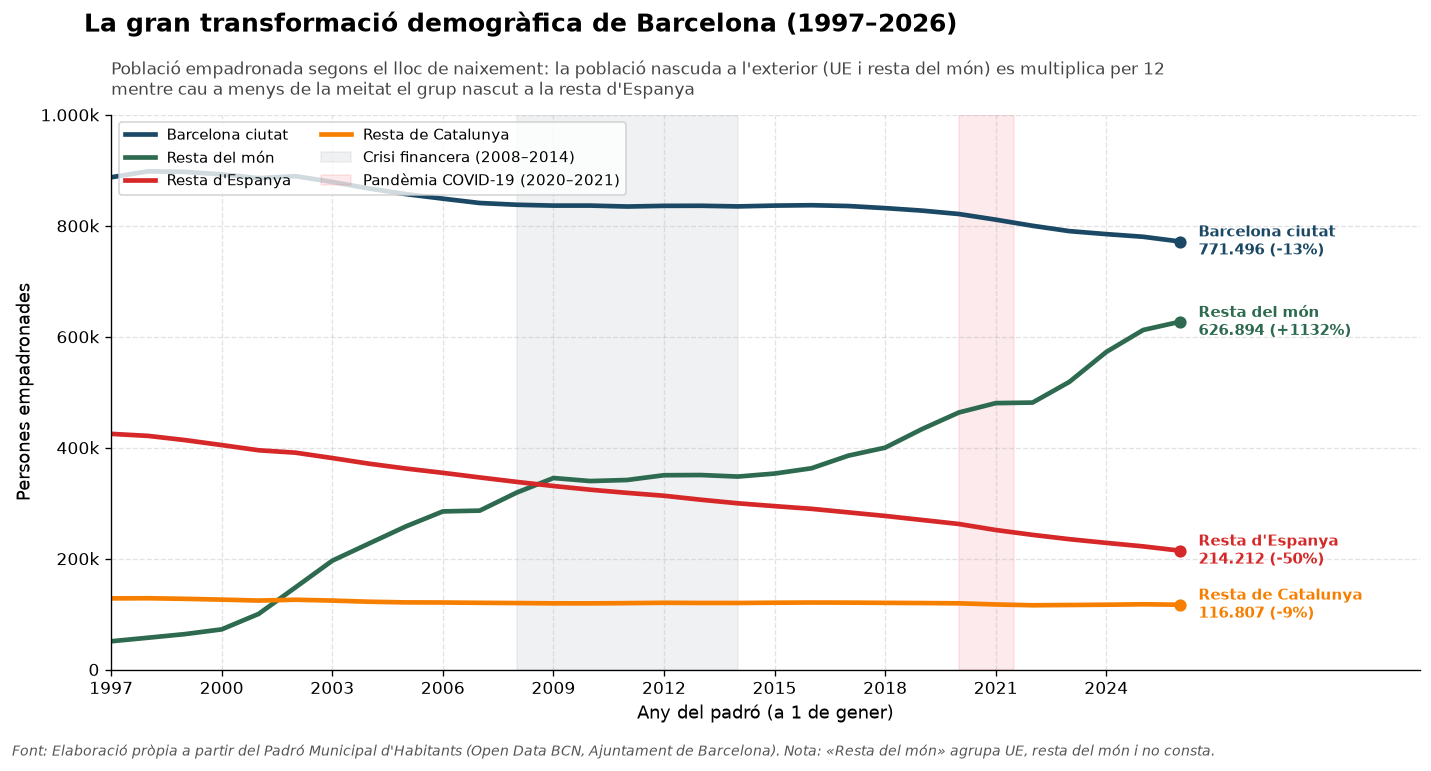

In [31]:
# 🔧 El millor gràfic, polit i complet
fig, ax = plt.subplots(figsize=(12, 6.2))

colors_polits = {
    "Barcelona ciutat": "#1b4965",
    "Resta del món": "#2d6a4f",
    "Resta d'Espanya": "#d62828",
    "Resta de Catalunya": "#f77f00",
}

for grup in ordre_grups:
    sub = serie_4grups[serie_4grups["Grup"] == grup].sort_values("Any")
    ax.plot(sub["Any"], sub["Total"], label=grup, color=colors_polits[grup], linewidth=2.8)
    val_1997 = int(sub.loc[sub["Any"] == 1997, "Total"].values[0])
    val_2026 = int(sub.loc[sub["Any"] == 2026, "Total"].values[0])
    variacio = ((val_2026 - val_1997) / val_1997) * 100
    signe = "+" if variacio > 0 else ""
    ax.scatter([2026], [val_2026], color=colors_polits[grup], s=40, zorder=5)
    ax.annotate(
        f"{grup}\n{val_2026:,} ({signe}{variacio:.0f}%)".replace(",", "."),
        xy=(2026, val_2026),
        xytext=(2026.5, val_2026),
        va="center",
        fontsize=9,
        fontweight="bold",
        color=colors_polits[grup],
    )

# Ombrejat de períodes clau
ax.axvspan(2008, 2014, color="#adb5bd", alpha=0.18, label="Crisi financera (2008–2014)")
ax.axvspan(2020, 2021.5, color="#e63946", alpha=0.10, label="Pandèmia COVID-19 (2020–2021)")

fig.suptitle(
    "La gran transformació demogràfica de Barcelona (1997–2026)",
    fontsize=15,
    fontweight="bold",
    x=0.06,
    y=0.98,
    ha="left",
)
ax.set_title(
    "Població empadronada segons el lloc de naixement: la població nascuda a l'exterior (UE i resta del món) es multiplica per 12\nmentre cau a menys de la meitat el grup nascut a la resta d'Espanya",
    fontsize=10,
    color="#444444",
    loc="left",
    pad=12,
)

ax.set_xlabel("Any del padró (a 1 de gener)", fontsize=10.5)
ax.set_ylabel("Persones empadronades", fontsize=10.5)
ax.set_xlim(1997, 2032.5)
ax.set_ylim(0, 1000000)
ax.set_xticks(range(1997, 2027, 3))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000):,}k".replace(",", ".") if x > 0 else "0"))
ax.legend(loc="upper left", frameon=True, ncol=2, fontsize=9)

fig.text(
    0.01,
    -0.02,
    "Font: Elaboració pròpia a partir del Padró Municipal d'Habitants (Open Data BCN, Ajuntament de Barcelona). Nota: «Resta del món» agrupa UE, resta del món i no consta.",
    fontsize=8.5,
    color="#555555",
    style="italic",
)

plt.tight_layout()
plt.show()


### 6.3 🔧 Una pregunta oberta

Proposa **una pregunta** que les dades disponibles NO poden respondre
però que seria rellevant per entendre millor la demografia de Barcelona.
Indica quin dataset addicional caldria per respondre-la.

**Pregunta proposada:**
*Fins a quin punt l'augment del preu del lloguer i de l'habitatge a cada barri de Barcelona explica la reducció del percentatge de llars amb menors d'edat i l'expulsió de famílies joves cap a d'altres municipis de l'Àrea Metropolitana?*

**Datasets addicionals necessaris:**
1. **Sèrie històrica del preu mitjà del lloguer i de compravenda per barri / secció censal** (disponible a través de l'INCASÒL i el portal Open Data BCN d'habitatge) juntament amb la **renda familiar disponible per càpita per barri**.
2. **Estadística de variacions residencials i baixes per emigració per edat i municipi de destinació** (Institut d'Estadística de Catalunya - IDESCAT / INE), per poder seguir si les llars amb infants deixen d'aparèixer perquè els fills es fan grans (>18 anys) o perquè les famílies es muden efectivament fora de Barcelona.
